<a href="https://colab.research.google.com/github/dapenuela/Transformers-/blob/main/01_Atencion_Serie_Temporal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atención temporal en una serie de tiempo
Diego Armando Peñuela Cárdenas · Especialización en Inteligencia Artificial

**Objetivo.** Predecir el siguiente valor de una serie sintética a partir de las 48 observaciones anteriores. En Colab, abrir este .ipynb y ejecutar todas las celdas en orden. Basta usar CPU.

## Preparación de datos
Se simulan dos ciclos (24 y 72 pasos), tendencia y ruido. La partición es cronológica (70/15/15 por instante objetivo). Se ajusta la normalización solo con entrenamiento. Cada ventana usa observaciones anteriores a su objetivo, aunque las primeras ventanas de validación o prueba usan historial de la partición anterior.

In [ ]:
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

torch.manual_seed(42)
torch.set_num_threads(2)
rng = np.random.default_rng(42)
t = np.arange(1440)
serie = (0.001*t + np.sin(2*np.pi*t/24)
         + 0.45*np.cos(2*np.pi*t/72) + rng.normal(0, 0.12, len(t)))
corte_train, corte_val = 1008, 1224
media, desviacion = serie[:corte_train].mean(), serie[:corte_train].std()
z = (serie - media) / desviacion
ventana = 48
indices = np.arange(ventana, len(z))
X = torch.tensor(np.stack([z[i-ventana:i] for i in indices]), dtype=torch.float32).unsqueeze(-1)
Y = torch.tensor(z[indices], dtype=torch.float32)
train, val, test = indices < corte_train, (indices >= corte_train)&(indices < corte_val), indices >= corte_val
print(f'PyTorch {torch.__version__} | Ventanas: {train.sum()} entrenamiento, {val.sum()} validación, {test.sum()} prueba')


PyTorch 2.15.0+cpu | Ventanas: 960 entrenamiento, 216 validación, 216 prueba


## Arquitectura
El último paso genera una consulta. Las claves representan los 48 pasos y los valores se promedian con pesos de atención. La capa final combina el contexto con el último paso.

In [ ]:
class Modelo(nn.Module):
    def __init__(self, d=24):
        super().__init__()
        self.proyeccion = nn.Linear(1, d)
        self.posicion = nn.Parameter(torch.randn(1, ventana, d) * 0.05)
        self.q, self.k, self.v = nn.Linear(d, d), nn.Linear(d, d), nn.Linear(d, d)
        self.salida = nn.Sequential(nn.Linear(2*d, d), nn.ReLU(), nn.Linear(d, 1))

    def forward(self, x, retornar_pesos=False):
        h = self.proyeccion(x) + self.posicion
        consulta = self.q(h[:, -1:, :])
        puntajes = consulta @ self.k(h).transpose(1, 2) / h.shape[-1]**0.5
        pesos = puntajes.softmax(dim=-1)
        contexto = (pesos @ self.v(h)).squeeze(1)
        pred = self.salida(torch.cat((contexto, h[:, -1, :]), dim=-1)).squeeze(-1)
        return (pred, pesos[:, 0, :]) if retornar_pesos else pred


## Entrenamiento
Se minimiza el MSE con Adam y se conservan los pesos de la época con menor MSE de validación.

In [ ]:
from copy import deepcopy

modelo = Modelo()
optimizador = torch.optim.Adam(modelo.parameters(), lr=0.002)
perdida = nn.MSELoss()
lotes = DataLoader(TensorDataset(X[train], Y[train]), batch_size=64, shuffle=True,
                   generator=torch.Generator().manual_seed(42))
hist_train, hist_val = [], []
mejor_mse = float('inf')
for epoca in range(1, 31):
    modelo.train()
    suma = 0.0
    for xb, yb in lotes:
        optimizador.zero_grad()
        error = perdida(modelo(xb), yb)
        error.backward()
        optimizador.step()
        suma += error.item()*len(yb)
    modelo.eval()
    with torch.no_grad():
        mse_val = perdida(modelo(X[val]), Y[val]).item()
    hist_train.append(suma/int(train.sum()))
    hist_val.append(mse_val)
    if mse_val < mejor_mse:
        mejor_mse, mejor_epoca = mse_val, epoca
        mejores_pesos = deepcopy(modelo.state_dict())
    if epoca in (1, 5, 10, 15, 20, 25, 30):
        print(f'Época {epoca:02d} | MSE entrenamiento {hist_train[-1]:.4f} | MSE validación {mse_val:.4f}')
modelo.load_state_dict(mejores_pesos)
print(f'Mejor época: {mejor_epoca} | MSE validación: {mejor_mse:.4f}')


Época 01 | MSE entrenamiento 0.5591 | MSE validación 0.2101
Época 05 | MSE entrenamiento 0.0801 | MSE validación 0.0745
Época 10 | MSE entrenamiento 0.0397 | MSE validación 0.0369
Época 15 | MSE entrenamiento 0.0382 | MSE validación 0.0359
Época 20 | MSE entrenamiento 0.0380 | MSE validación 0.0368
Época 25 | MSE entrenamiento 0.0380 | MSE validación 0.0376
Época 30 | MSE entrenamiento 0.0373 | MSE validación 0.0365
Mejor época: 29 | MSE validación: 0.0345


## Evaluación
Se usa pronóstico a un paso con historial observado. Las métricas MAE y RMSE se calculan en la escala original y se comparan con persistencia y repetición del valor de hace 24 pasos.

Persistencia: MAE=0.2073 | RMSE=0.2598
Estacional (24 pasos): MAE=0.4916 | RMSE=0.5585
Modelo: MAE=0.1525 | RMSE=0.1879


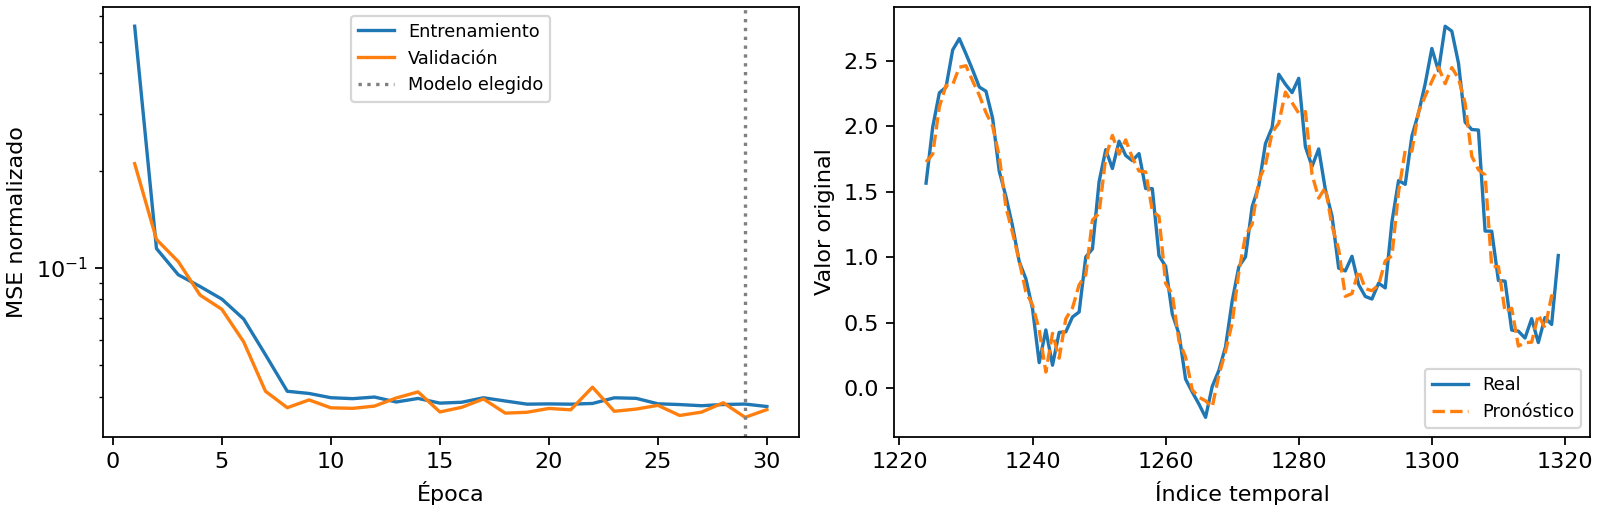

In [ ]:
modelo.eval()
with torch.no_grad():
    pred = modelo(X[test]).numpy()*desviacion + media
real = serie[indices[test]]
def metricas(prediccion):
    error = prediccion-real
    return np.abs(error).mean(), np.sqrt(np.mean(error**2))

for nombre, estimacion in [('Persistencia', serie[indices[test]-1]),
                            ('Estacional (24 pasos)', serie[indices[test]-24]),
                            ('Modelo', pred)]:
    mae, rmse = metricas(estimacion)
    print(f'{nombre}: MAE={mae:.4f} | RMSE={rmse:.4f}')
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), layout='constrained')
axes[0].plot(range(1,31), hist_train, label='Entrenamiento')
axes[0].plot(range(1,31), hist_val, label='Validación')
axes[0].axvline(mejor_epoca, color='gray', linestyle=':', label='Modelo elegido')
axes[0].set(xlabel='Época', ylabel='MSE normalizado', yscale='log')
axes[1].plot(indices[test][:96], real[:96], label='Real')
axes[1].plot(indices[test][:96], pred[:96], '--', label='Pronóstico')
axes[1].set(xlabel='Índice temporal', ylabel='Valor original')
for ax in axes:
    ax.legend(fontsize=8)
plt.show()


## Inspección de los pesos
Los pesos indican cómo se combinan los valores proyectados en esta ventana y por sí solos no establecen causalidad.

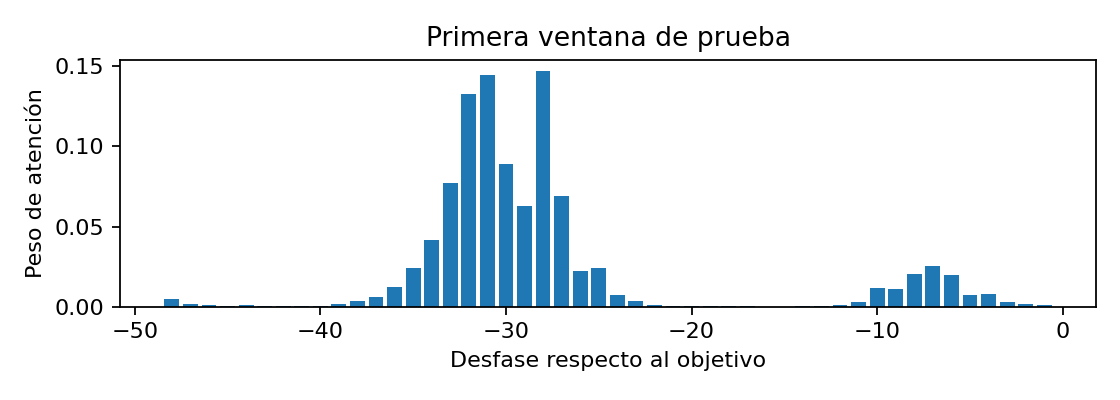

In [ ]:
with torch.no_grad():
    _, pesos = modelo(X[test][:1], retornar_pesos=True)
plt.figure(figsize=(7, 2.5))
plt.bar(np.arange(-ventana, 0), pesos[0].numpy())
plt.xlabel('Desfase respecto al objetivo')
plt.ylabel('Peso de atención')
plt.title('Primera ventana de prueba')
plt.tight_layout()
plt.show()
